# Basic Probability Distributions in R

A **probability distribution** describes how probability mass (discrete case) or probability density (continuous case) is spread across possible outcomes.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Discrete vs Continuous

**Discrete** distributions are defined for **countable** outcomes via a **Probability Mass Function (PMF)**:
$$
P(X = x) = f(x), \qquad f(x) \ge 0, \qquad \sum_x f(x) = 1
$$

**Continuous** distributions are defined on intervals via a **Probability Density Function (PDF)**:
$$
f(x) \ge 0, \qquad \int_{-\infty}^{\infty} f(x)\,dx = 1, \qquad P(a \le X \le b) = \int_a^b f(x)\,dx
$$
For a continuous variable $P(X = x) = 0$ for any single value — only intervals have probability.

## 2. The Distributions You Need Most

| Distribution | Type | Parameters | Models | Mean | Variance |
|---|---|---|---|---|---|
| Binomial | discrete | $n, p$ | # successes in $n$ trials | $np$ | $np(1-p)$ |
| Poisson | discrete | $\lambda$ | # events in a fixed interval | $\lambda$ | $\lambda$ |
| Uniform | continuous | $a, b$ | "any value equally likely" | $\frac{a+b}{2}$ | $\frac{(b-a)^2}{12}$ |
| Normal | continuous | $\mu, \sigma$ | sums/averages, measurement error | $\mu$ | $\sigma^2$ |
| Exponential | continuous | $\lambda$ | waiting time between events | $1/\lambda$ | $1/\lambda^2$ |

PMFs/PDFs:
$$
\text{Binomial: } P(X=k) = \binom{n}{k}p^k(1-p)^{n-k} \qquad
\text{Poisson: } P(X=k) = \frac{\lambda^k e^{-\lambda}}{k!}
$$
$$
\text{Normal: } f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big) \qquad
\text{Exponential: } f(x) = \lambda e^{-\lambda x},\; x \ge 0
$$

## 3. R's Four Prefixes

Every distribution in R comes with four functions. For the normal distribution:

| Prefix | Meaning | Example |
|---|---|---|
| `d` | density / PMF | `dnorm(0)` = height of the curve at 0 |
| `p` | cumulative probability $P(X \le x)$ | `pnorm(1.96)` ≈ 0.975 |
| `q` | quantile (inverse of `p`) | `qnorm(0.975)` ≈ 1.96 |
| `r` | random sample | `rnorm(100)` |

In [2]:
### Binomial: 10 coin flips
n <- 10; p <- 0.5
x_vals_binom <- 0:n
prob_binom <- dbinom(x_vals_binom, size = n, prob = p)
print("Binomial PMF values (n=10, p=0.5):")
print(round(prob_binom, 4))
cat("Sum of PMF            :", sum(prob_binom), "\n")
cat("P(X = 5)              :", round(dbinom(5, n, p), 4), "\n")
cat("P(X <= 3)             :", round(pbinom(3, n, p), 4), "\n")
cat("P(X >= 8)             :", round(1 - pbinom(7, n, p), 4), "\n")

### Normal
cat("\nP(Z <= 1.96)          :", round(pnorm(1.96), 4), "\n")
cat("P(-1 <= Z <= 1)       :", round(pnorm(1) - pnorm(-1), 4), "  (the 68% rule)\n")
cat("97.5% quantile qnorm  :", round(qnorm(0.975), 4), "\n")

### Poisson: a call centre receives on average 4 calls per minute
cat("\nP(exactly 6 calls)    :", round(dpois(6, lambda = 4), 4), "\n")
cat("P(no calls)           :", round(dpois(0, lambda = 4), 4), "\n")

[1] "Binomial PMF values (n=10, p=0.5):"


 [1] 0.0010 0.0098 0.0439 0.1172 0.2051 0.2461 0.2051 0.1172 0.0439 0.0098
[11] 0.0010


Sum of PMF            : 1 


P(X = 5)              : 0.2461 


P(X <= 3)             : 0.1719 


P(X >= 8)             : 0.0547 



P(Z <= 1.96)          : 0.975 


P(-1 <= Z <= 1)       : 0.6827   (the 68% rule)


97.5% quantile qnorm  : 1.96 



P(exactly 6 calls)    : 0.1042 


P(no calls)           : 0.0183 


## 4. Visualising the Distributions

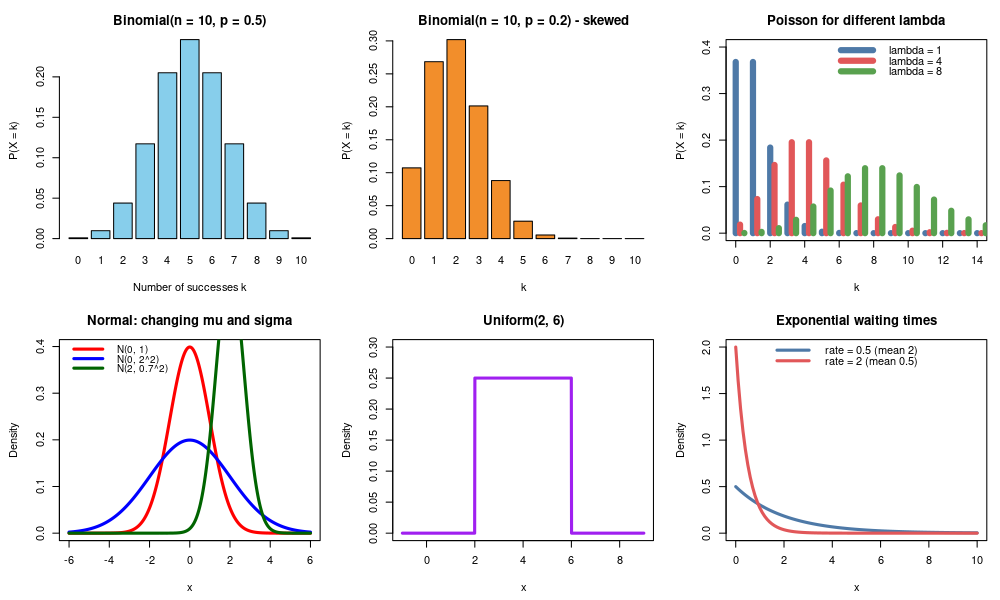

In [3]:
par(mfrow = c(2, 3), mar = c(4.5, 4.5, 3, 1))

barplot(prob_binom, names.arg = x_vals_binom, col = "skyblue",
        main = "Binomial(n = 10, p = 0.5)", xlab = "Number of successes k", ylab = "P(X = k)")

barplot(dbinom(0:10, 10, 0.2), names.arg = 0:10, col = "#F28E2B",
        main = "Binomial(n = 10, p = 0.2) - skewed", xlab = "k", ylab = "P(X = k)")

k <- 0:14
plot(k, dpois(k, 1), type = "h", lwd = 6, col = "#4E79A7", ylim = c(0, 0.4),
     main = "Poisson for different lambda", xlab = "k", ylab = "P(X = k)")
points(k + 0.25, dpois(k, 4), type = "h", lwd = 6, col = "#E15759")
points(k + 0.5, dpois(k, 8), type = "h", lwd = 6, col = "#59A14F")
legend("topright", c("lambda = 1", "lambda = 4", "lambda = 8"),
       col = c("#4E79A7", "#E15759", "#59A14F"), lwd = 6, bty = "n")

xs <- seq(-6, 6, length.out = 400)
plot(xs, dnorm(xs, 0, 1), type = "l", lwd = 3, col = "red", main = "Normal: changing mu and sigma",
     xlab = "x", ylab = "Density")
lines(xs, dnorm(xs, 0, 2), lwd = 3, col = "blue")
lines(xs, dnorm(xs, 2, 0.7), lwd = 3, col = "darkgreen")
legend("topleft", c("N(0, 1)", "N(0, 2^2)", "N(2, 0.7^2)"), col = c("red", "blue", "darkgreen"),
       lwd = 3, bty = "n", cex = 0.9)

curve(dunif(x, 2, 6), -1, 9, n = 1000, lwd = 3, col = "purple", ylim = c(0, 0.3),
      main = "Uniform(2, 6)", xlab = "x", ylab = "Density")

curve(dexp(x, 0.5), 0, 10, lwd = 3, col = "#4E79A7", ylim = c(0, 2),
      main = "Exponential waiting times", xlab = "x", ylab = "Density")
curve(dexp(x, 2), 0, 10, lwd = 3, col = "#E15759", add = TRUE)
legend("topright", c("rate = 0.5 (mean 2)", "rate = 2 (mean 0.5)"), col = c("#4E79A7", "#E15759"),
       lwd = 3, bty = "n")

## 5. Probability as Area Under the Curve

For a continuous variable, a probability is an **area**. Below: $P(-1 \le Z \le 1)$ and $P(Z > 1.645)$ for the standard normal.

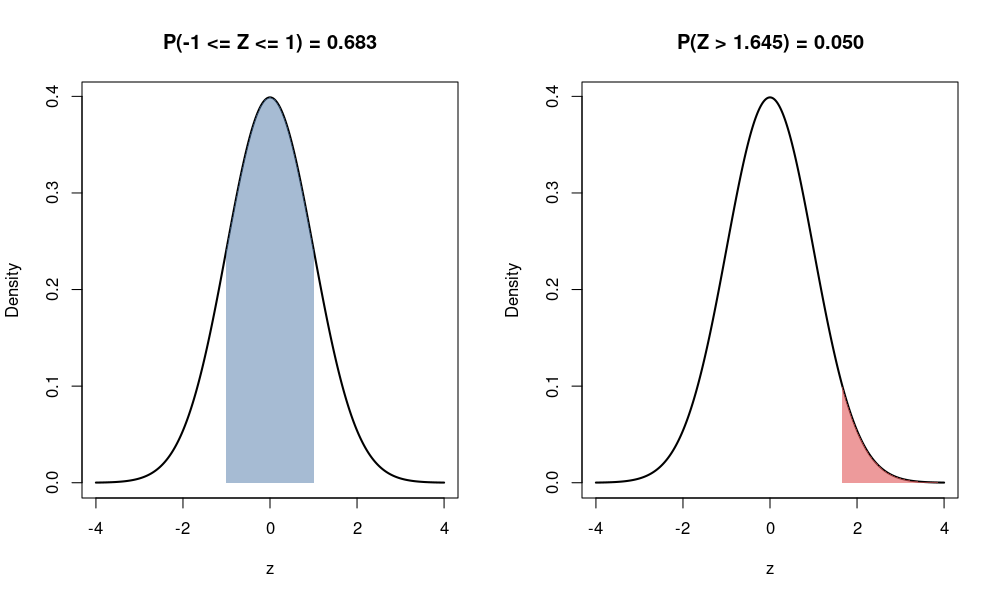

In [4]:
par(mfrow = c(1, 2))
shade <- function(lo, hi, col) {
  xx <- seq(lo, hi, length.out = 200)
  polygon(c(lo, xx, hi), c(0, dnorm(xx), 0), col = col, border = NA)
}
xs <- seq(-4, 4, length.out = 400)

plot(xs, dnorm(xs), type = "l", lwd = 2, main = sprintf("P(-1 <= Z <= 1) = %.3f", pnorm(1) - pnorm(-1)),
     xlab = "z", ylab = "Density")
shade(-1, 1, adjustcolor("#4E79A7", 0.5))

plot(xs, dnorm(xs), type = "l", lwd = 2, main = sprintf("P(Z > 1.645) = %.3f", 1 - pnorm(1.645)),
     xlab = "z", ylab = "Density")
shade(1.645, 4, adjustcolor("#E15759", 0.6))

## 6. Simulation vs Theory

Drawing random samples with the `r*` functions and comparing them to the theoretical curve is the best way to build intuition (and to check your understanding).

Simulated binomial mean/var: 5.003 / 2.558  (theory: 5 / 2.5)


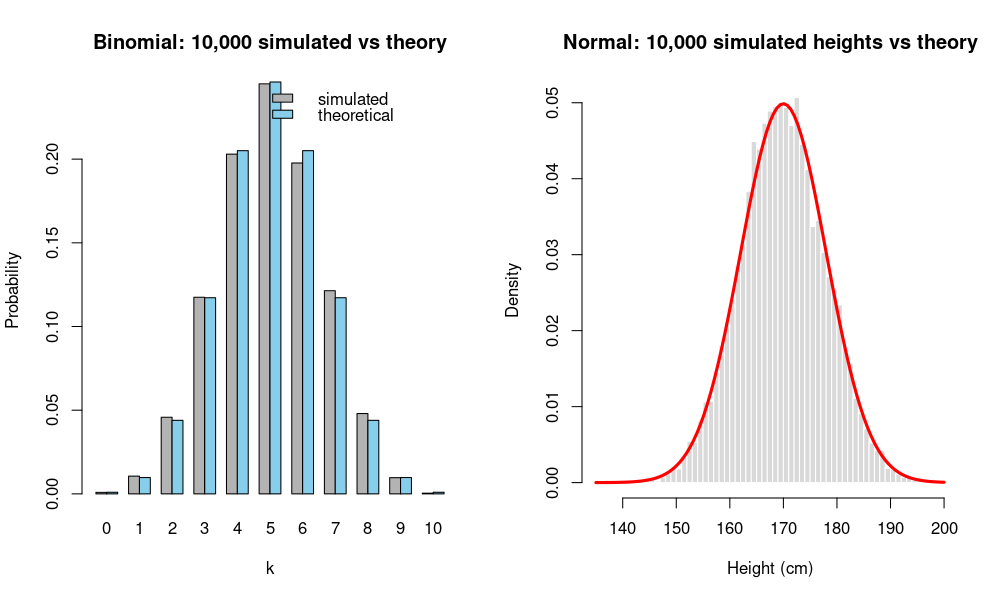

In [5]:
set.seed(1)
sim_binom <- rbinom(10000, size = 10, prob = 0.5)
sim_norm  <- rnorm(10000, mean = 170, sd = 8)

par(mfrow = c(1, 2))
emp <- table(factor(sim_binom, levels = 0:10)) / length(sim_binom)
bp <- barplot(rbind(emp, dbinom(0:10, 10, 0.5)), beside = TRUE, names.arg = 0:10,
              col = c("grey70", "skyblue"), main = "Binomial: 10,000 simulated vs theory",
              xlab = "k", ylab = "Probability")
legend("topright", c("simulated", "theoretical"), fill = c("grey70", "skyblue"), bty = "n")

hist(sim_norm, breaks = 50, freq = FALSE, col = "grey85", border = "white",
     main = "Normal: 10,000 simulated heights vs theory", xlab = "Height (cm)")
curve(dnorm(x, 170, 8), add = TRUE, col = "red", lwd = 3)

cat("Simulated binomial mean/var:", round(mean(sim_binom), 3), "/", round(var(sim_binom), 3),
    " (theory: 5 / 2.5)\n")

*Insight: Notice the Poisson's mean equals its variance ($\lambda$). If real count data shows a variance much larger than its mean, a Poisson model is the wrong choice — this is called **overdispersion**, and it comes back in Lesson 27 (GLMs).*

## Real-World Use Case or Analogy

- **Binomial**: the number of defective items in a batch of 50, if each is defective with probability 2%.
- **Poisson**: the number of customers entering a shop per minute, or emails arriving per hour.
- **Normal**: heights, weights, measurement errors — anything made of many small additive effects.
- **Exponential**: the waiting time until the next bus arrives or the next server failure.
- **Uniform**: a random number generator, or the arrival time of a guest told to "come between 2 and 6".

Picking a distribution is like picking the right **container**: water goes in a bottle, sand in a bag. Using the wrong one (e.g., a normal model for counts that can't be negative) means your predictions will leak.